# Classifying Cancer Types Using Gene Expression RNA-Seq Data

---
embed-resources: true
echo: false
warning: false
message: false
---

## Introduction

Cancer detection and classification are important challenges in modern healthcare, as early and accurate diagnosis can significantly improve patient outcomes and treatment decisions. Advances in next-generation sequencing technologies such as RNA-Seq have made it possible to measure gene expression levels across thousands of genes, providing detailed biological information that may help distinguish between different cancer types. As these technologies become more affordable and accessible, biotechnology companies are increasingly interested in using machine learning models to analyze genetic data and support cancer detection and classification. This report investigates whether machine learning models can effectively classify cancer types using gene expression RNA-Seq data collected from cancer tissue samples as part of a proof-of-concept project for a biotechnology startup exploring the development of a universal cancer detection system. The dataset contains gene expression measurements for multiple cancer types, including breast, prostate, kidney, lung, and colon cancers, and the goal is to develop a model that accurately predicts cancer classification based on gene expression patterns while demonstrating the potential usefulness of machine learning methods in genomic cancer analysis.

## Methods

In [1]:
# imports
import pandas as pd
import numpy as np
from joblib import dump
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix

### Data

In [2]:
# load data
genetics = pd.read_csv(
    "genetics-data.csv",
)

In [3]:
# split data
genetics_train, genetics_test = train_test_split(
    genetics,
    test_size=0.20,
    stratify=genetics["cancer"],
    random_state=307,
)

The dataset contains gene expression information collected from cancer tissue samples. Each observation represents a single patient sample and includes the following variables:

| Category | Variable | Type | Description |
|----------|----------|------|-------------|
| Response | cancer | object | Clinically determined cancer type classification. One of: BRCA (Breast Invasive Carcinoma), PRAD (Prostate Adenocarcinoma), KIRC (Kidney Renal Clear Cell Carcinoma), LUAD (Lung Adenocarcinoma), or COAD (Colon Adenocarcinoma). |
| Features | gene_#### | float64 | Gene expression quantification for gene number #### in the dataset as measured by an Illumina HiSeq RNA-Seq platform. |

Shape of the dataset:

In [4]:
# summary statistics
genetics_train.shape

(640, 4001)

Number of each cancer type:

In [5]:
genetics_train[["cancer"]].value_counts()

cancer
BRCA      240
KIRC      116
LUAD      113
PRAD      109
COAD       62
Name: count, dtype: int64

My summary statistics show that the training dataset contains 640 observations and 4000 features, including the response variable and thousands of gene expression features. I also examined the distribution of cancer types within the dataset and found that BRCA is the most common cancer classification with 240 observations, while COAD is the least common with 62 observations. The remaining cancer types, including KIRC, LUAD, and PRAD, appear in moderate amounts throughout the dataset. Although the classes are not perfectly balanced, each cancer type is still represented by a meaningful number of observations, which helps support machine learning model development and evaluation. The large number of numerical gene expression variables suggests that the dataset contains substantial biological information that may help distinguish between different cancer classifications.

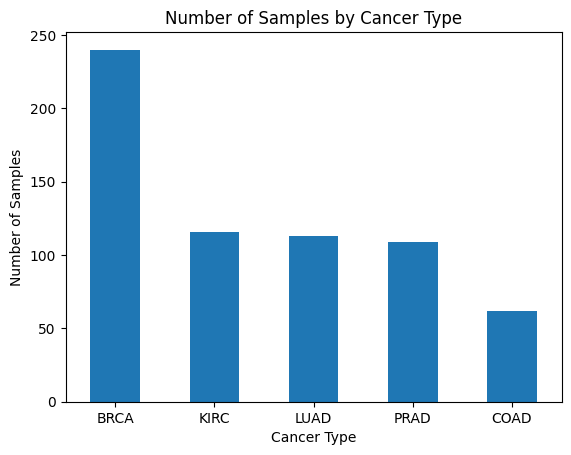

In [6]:
#| fig-cap: "Figure 1. Number of Samples by Cancer Type in the Data"
# exploratory visualization
cancer_counts = genetics_train["cancer"].value_counts()

cancer_counts.plot(kind="bar")

plt.xlabel("Cancer Type")
plt.ylabel("Number of Samples")
plt.title("Number of Samples by Cancer Type")

plt.xticks(rotation=0)

plt.show()

### Models

In [7]:
# process data for ML
X_train = genetics_train.drop("cancer",axis=1,)
y_train = genetics_train["cancer"]

X_test = genetics_test.drop("cancer",axis=1,)
y_test = genetics_test["cancer"]

In [8]:
# train model
model = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="median",
            ),
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=700,
                max_depth=None,
                min_samples_leaf=1,
                max_features="sqrt",
                random_state=307,
                n_jobs=-1,
            ),
        ),
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['BRCA','COAD','KIRC','LUAD','PRAD']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4000,)","['gene_0','gene_1','gene_2',...,'gene_3997','gene_3998','gene_3999']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4000
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_

The cancer classification task was treated as a multiclass classification problem, where the goal is to predict the clinically determined cancer type using gene expression RNA-Seq data. A Random Forest classifier was selected because it performs well on high-dimensional numerical datasets and can capture complex nonlinear relationships between gene expression variables and cancer classifications. The model was trained using 700 decision trees with square-root feature sampling to improve generalization and reduce overfitting while still allowing the model to learn meaningful biological patterns from thousands of gene expression variables. Since the dataset consists entirely of numerical gene expression measurements, a preprocessing pipeline was implemented using a Pipeline object with median imputation to handle any potential missing values before model training. The dataset was separated into training and testing datasets using a stratified 80/20 split to preserve the distribution of cancer types across both datasets. After training, the model was used to generate predictions on unseen test data, and performance was evaluated using classification metrics including accuracy, precision, and recall to assess the effectiveness of the cancer classification system.

## Results

In [9]:
# report model metrics
y_pred = model.predict(
    X_test
)

test_accuracy = accuracy_score(
    y_test,
    y_pred,
)

test_precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
)

test_recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
)

print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)

Test Accuracy: 1.0
Test Precision: 1.0
Test Recall: 1.0


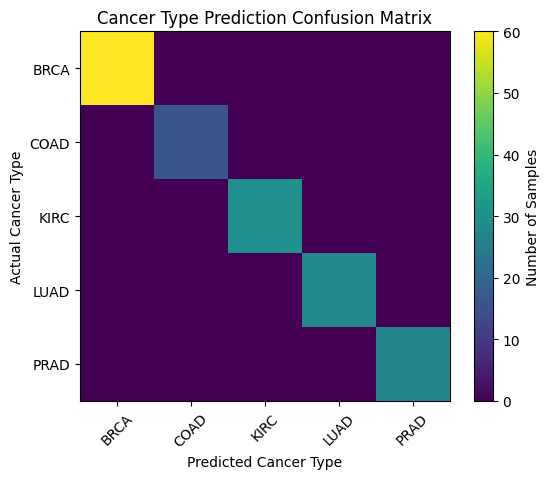

In [10]:
#| fig-cap: "Figure 2. Confusion Matrix for Cancer Type Predictions on the Test Data"
# summary figure
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_,
)

plt.figure()

plt.imshow(cm)

plt.xlabel("Predicted Cancer Type")
plt.ylabel("Actual Cancer Type")
plt.title("Cancer Type Prediction Confusion Matrix")

plt.xticks(
    range(len(model.classes_)),
    model.classes_,
    rotation=45,
)

plt.yticks(
    range(len(model.classes_)),
    model.classes_,
)

plt.colorbar(label="Number of Samples")

plt.show()

Overall, the results indicate that the Random Forest model provides extremely strong performance for classifying cancer types using gene expression RNA-Seq data. The model achieved a test accuracy, precision, and recall of 1.0 on the unseen test dataset, indicating that all cancer samples in the test set were correctly classified. These results suggest that the gene expression variables contain highly informative biological patterns that strongly differentiate the five cancer types included in the dataset. The confusion matrix further supports this result, as all observations appear along the main diagonal with no visible off-diagonal misclassifications, indicating that the model successfully predicted each cancer category without error on the test data. Together, these results demonstrate that machine learning models can effectively identify meaningful relationships within high-dimensional gene expression data and accurately classify cancer types. However, despite the near-perfect performance, these results should still be interpreted carefully because the dataset is relatively controlled and limited to five cancer classes, meaning real-world clinical performance may be lower when applied to more diverse patient populations and additional cancer subtypes.

## Discussion

Based on the results presented above, I would recommend continuing development of this model as part of a proof-of-concept cancer classification system for the biotechnology startup. The Random Forest model demonstrated extremely strong performance on the test dataset, achieving perfect accuracy, precision, and recall across all five cancer classifications. These results suggest that gene expression RNA-Seq data contains highly informative biological patterns that can effectively distinguish between different cancer types. The confusion matrix further supports this conclusion, as the model correctly classified all cancer samples without visible misclassification errors on the unseen test data.

One important benefit of this model is its ability to analyze thousands of gene expression variables simultaneously and identify complex nonlinear relationships within high-dimensional biological data. Traditional cancer diagnosis often requires multiple clinical tests and expert interpretation, while a machine learning system based on RNA-Seq data could potentially provide rapid and automated cancer classification support. In practice, this type of system could help researchers and healthcare professionals better understand cancer biology, assist in identifying cancer subtypes, and potentially support earlier detection and treatment planning. Because Random Forest models can capture interactions across many gene expression variables, the model is capable of learning biological patterns that may not be obvious through manual analysis alone.

However, several important limitations should still be considered before using this model in a real clinical environment. Although the model achieved perfect performance on the provided dataset, the dataset itself is relatively controlled and limited to five cancer types. Real-world medical data is often significantly more complex, noisy, and diverse than curated research datasets. Additional challenges such as patient variability, sequencing errors, rare cancer subtypes, and differences between hospitals or sequencing platforms could reduce real-world performance. The model also relies entirely on gene expression information and does not incorporate other clinically important factors such as imaging data, patient history, genetic mutations, environmental factors, or physician observations.

For these reasons, the model should not be used as a fully automated medical decision-making system without expert oversight. Instead, it would be most effective as part of a clinical decision-support system where predictions generated by the model are reviewed alongside additional medical evidence and professional judgment. This approach would allow healthcare professionals to benefit from the model’s predictive capabilities while reducing the risks associated with relying entirely on automated predictions in high-stakes medical settings.

Overall, the results demonstrate that machine learning models can effectively classify cancer types using gene expression RNA-Seq data. While the current model still has limitations and would require additional validation before clinical deployment, the strong predictive performance suggests that machine learning-based genomic cancer classification is a promising area for future biotechnology and healthcare research.